# Dynamic updating: revising the day's forecast from the morning

`notebooks/shang_replication.ipynb` forecasts a whole trading session at the close of the
session before, and then says nothing. By mid-morning the first part of the day has actually
been observed, and the question is what the rest of it looks like given that. Shang & Hyndman
(2011) call this **dynamic updating**, and it is the second half of both of Shang's 2017 papers.

Write the intraday grid as an observed block $o = (s_1, \dots, s_m)$ and an unobserved block
$u = (s_{m+1}, \dots, s_N)$. The decomposition of the historical curves is unchanged,
$X_t = \mu + \sum_k \psi_{t,k}\phi_k$, and every method is a different answer to one question:
which score vector $\mathbf{b}$ to rebuild the unobserved block from.

$$
\begin{aligned}
\texttt{ts}\;&: \quad \mathbf{b} = \hat{\boldsymbol\psi}_{n+1} && \text{the day-ahead
forecast, ignoring what has been seen}\\
\texttt{ols}\;&: \quad \mathbf{b} = \arg\min_{\mathbf b}\;
\lVert X_o - \mu_o - \Phi_o^\top \mathbf b\rVert^2 && \text{regress the observed block on the
components}\\
\texttt{ridge}\;&: \quad + \;\lambda\lVert \mathbf b\rVert^2 && \text{shrink toward the mean
curve}\\
\texttt{pls}\;&: \quad + \;\lambda\lVert \mathbf b - \hat{\boldsymbol\psi}_{n+1}\rVert^2 &&
\text{shrink toward the day-ahead forecast}
\end{aligned}
$$

The last is Shang & Hyndman's penalised least squares update, and it is the one that
interpolates: $\lambda = 0$ is `ols`, $\lambda \to \infty$ is `ts`. A fifth method,
**block moving**, uses no regression at all. It rotates the day boundary to the update point,
so the historical days and the observed morning become complete curves on a rotated domain;
forecasting the next one and reading off its leading $N - m$ points answers the question
without a design matrix to invert.

**A cumulative curve needs one benchmark more than usual.** $X_{n+1}(s)$ for $s$ in $u$ is a
*cumulative* return, so most of it is $X_{n+1}(s_m)$, which has already been observed. A method
that merely reproduces the level will look accurate without having forecast anything. The
benchmark that separates the two is `hold`, which carries the last observed value forward and
predicts no further move. On a cumulative return that is the martingale, and the out-of-sample
$R^2$ against it is exactly the $R^2$ for predicting the *increment* $X(s) - X(s_m)$, which is
the only part not already known.

`ftsa/README.md` documents the implementation and carries the references.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

from fts_research.core import style
from fts_research.ftsa import evaluation as ev
from fts_research.ftsa import forecast as fc
from fts_research.ftsa import updating as up

style.use(plt)

X, grid, dates = ev.replication_curves()

# The four fitted methods take hues; the day-ahead forecast and the two benchmarks are what
# they are measured against, so they are ink and grey rather than a fifth and sixth colour.
COLOUR = {"ols": style.CATEGORICAL[0], "ridge": style.CATEGORICAL[1],
          "pls": style.CATEGORICAL[2], "block": style.SEQUENTIAL_STEPS[-1],
          "ts": style.INK, "hold": style.CONTROL, "mean": "#b9b8b2"}
LABEL = {"ts": "no update", "ols": "least squares", "ridge": "ridge", "pls": "penalised LS",
         "block": "block moving", "hold": "hold (martingale)", "mean": "mean curve, shifted"}

print(f"{X.shape[0]} sessions on {grid.size} intraday points")
print(f"update points swept: {up.UPDATE_FRACTIONS}")
print(f"methods: {up.METHODS}")

125 sessions on 78 intraday points
update points swept: (0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9)
methods: ('ts', 'ols', 'ridge', 'pls', 'block', 'hold', 'mean')


## 1. One session, updated

The clearest way to see what each method does is to watch one held-out day. The one taken is
the held-out session that had moved furthest by the update point, since that is where the
difference between using the morning and ignoring it has the most to show; it is observed to
30% and every method is asked for the rest of it, from a decomposition fitted on the sessions
before it and nothing else.

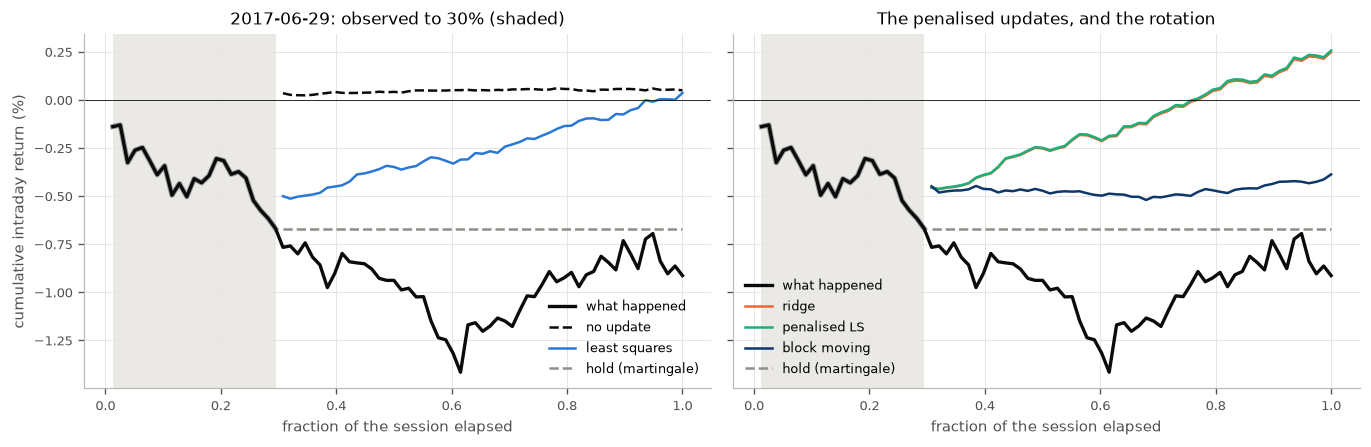

2017-06-29: -0.6692% by the update point, closing -0.9135%, having reached -1.4160%
observed to point 23 of 78, 2 components retained
root mean squared error over the remainder:
  no update            1.0167%
  least squares        0.7352%
  ridge                0.8783%
  penalised LS         0.8836%
  block moving         0.5085%
  hold (martingale)    0.3294%
  mean curve, shifted  0.3475%


In [2]:
fraction = 0.3
m = up.split_index(grid, fraction)

held_out = np.arange(max(int(np.floor(ev.CONFIG["init_frac"] * len(X))), 10), len(X))
day = int(held_out[np.argmax(np.abs(X[held_out, m - 1]))])
history, head = X[:day], X[day, :m]
dec = fc.decompose(history, grid)
beta_ts = fc.forecast_scores(dec["scores"], h=1, method="far")["point"][0]

predictions = {}
for method in up.METHODS:
    predictions[method] = up.update_curve(history, grid, head, method=method, dec=dec,
                                          beta_ts=beta_ts)["prediction"]

fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8), sharey=True)
for axis, shown in zip(ax, (("ts", "ols", "hold"), ("ridge", "pls", "block", "hold"))):
    axis.axvspan(grid[0], grid[m - 1], color=style.BAND, alpha=0.55, lw=0)
    axis.plot(grid, X[day], color=style.INK, lw=2, label="what happened")
    axis.plot(grid[:m], head, color=style.INK, lw=3.2, alpha=0.35)
    for method in shown:
        axis.plot(grid[m:], predictions[method], color=COLOUR[method], lw=1.5,
                  ls="--" if method in ("ts", "hold") else "-", label=LABEL[method])
    axis.axhline(0, color=style.INK, lw=0.5)
    axis.set_xlabel("fraction of the session elapsed")
    axis.legend()
ax[0].set_ylabel("cumulative intraday return (%)")
ax[0].set_title(f"{dates[day]}: observed to {fraction:.0%} (shaded)")
ax[1].set_title("The penalised updates, and the rotation")
plt.tight_layout()
plt.show()

print(f"{dates[day]}: {X[day, m - 1]:+.4f}% by the update point, closing "
      f"{X[day, -1]:+.4f}%, having reached {X[day, m:].min():+.4f}%")
print(f"observed to point {m} of {grid.size}, {dec['n_components']} components retained")
print("root mean squared error over the remainder:")
for method in up.METHODS:
    error = np.sqrt(np.mean((X[day, m:] - predictions[method]) ** 2))
    print(f"  {LABEL[method]:<20} {error:.4f}%")

Two things are visible. The day-ahead forecast is a nearly flat line just above zero, on a
session that was already down two thirds of a per cent when it was made, which is what dynamic
updating is for. And every method that does look at the morning starts from roughly the right
place and then drifts back up toward zero, because the mean curve it is expanded around is
close to flat and only two components are retained. On this day that drift is wrong: the
session went on falling. Carrying the last observed value forward is the closest of the seven.

## 2. Does updating help?

The first question is Shang's own, and it does not involve the benchmarks: measured against the
un-updated forecast, does using the morning improve the afternoon? The sweep below runs every
method at nine update points, on an expanding window over the same fifty held-out sessions the
replication notebook used, and is read back from `artifacts/cache/`.

In [3]:
records = up.cached_updating()
table = up.summarise_updates(records)
plain = table.xs(False, level="anchored")

msfe = plain["msfe"].unstack("method")[list(up.METHODS)]
print("mean squared forecast error over the unobserved block:")
print(msfe.round(4).to_string())

print("\nproportion of the un-updated error removed:")
print((1 - msfe.div(msfe["ts"], axis=0)).drop(columns="ts").round(3).to_string())

mean squared forecast error over the unobserved block:
method        ts     ols   ridge     pls   block    hold    mean
fraction                                                        
0.1       0.0733  0.5197  0.0678  0.0698  0.0732  0.0344  0.0346
0.2       0.0777  0.7935  0.0843  0.0901  0.0375  0.0365  0.0369
0.3       0.0819  0.2079  0.0861  0.0870  0.0322  0.0253  0.0256
0.4       0.0866  0.1028  0.0680  0.0686  0.0309  0.0240  0.0248
0.5       0.0922  0.0460  0.0424  0.0427  0.0291  0.0171  0.0178
0.6       0.0957  0.0376  0.0332  0.0334  0.0274  0.0180  0.0183
0.7       0.0973  0.0329  0.0292  0.0289  0.0240  0.0118  0.0118
0.8       0.0976  0.0178  0.0168  0.0168  0.0171  0.0080  0.0082
0.9       0.0941  0.0114  0.0110  0.0110  0.0107  0.0076  0.0077

proportion of the un-updated error removed:
method      ols  ridge    pls  block   hold   mean
fraction                                          
0.1      -6.092  0.075  0.048  0.001  0.531  0.528
0.2      -9.212 -0.084 -0.160  0

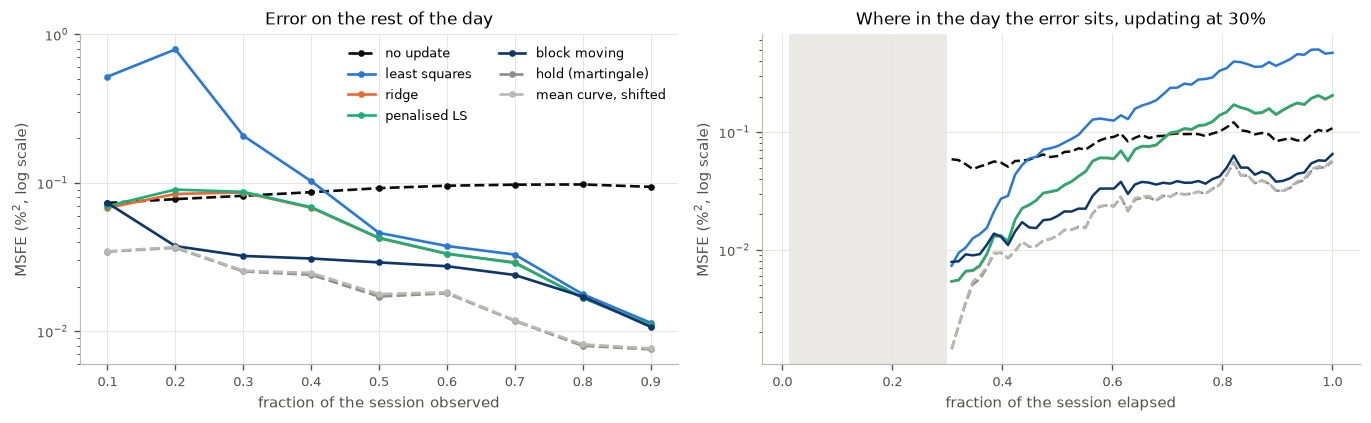

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.6))
for method in up.METHODS:
    ax[0].plot(msfe.index, msfe[method], color=COLOUR[method], lw=1.6,
               ls="--" if method in ("ts", "hold", "mean") else "-",
               marker="o", ms=3, label=LABEL[method])
ax[0].set_yscale("log")
ax[0].set_xlabel("fraction of the session observed")
ax[0].set_ylabel("MSFE (%$^2$, log scale)")
ax[0].set_title("Error on the rest of the day")
ax[0].legend(ncol=2)

profile = up.cached_profiles()
cell = profile[(profile["fraction"] == 0.3) & (~profile["anchored"])]
for method in up.METHODS:
    part = cell[cell["method"] == method].sort_values("s")
    ax[1].plot(part["s"], part["msfe"], color=COLOUR[method], lw=1.5,
               ls="--" if method in ("ts", "hold", "mean") else "-", label=LABEL[method])
ax[1].axvspan(grid[0], 0.3, color=style.BAND, alpha=0.55, lw=0)
ax[1].set_yscale("log")
ax[1].set_xlabel("fraction of the session elapsed")
ax[1].set_ylabel("MSFE (%$^2$, log scale)")
ax[1].set_title("Where in the day the error sits, updating at 30%")
plt.tight_layout()
plt.show()

Shang's claim reproduces, with one qualification about where it starts. From 40% of the
session onwards every method that looks at the morning beats the forecast that does not, and
the margin then grows steadily: by the last fifth of the day the penalised updates have removed
above 82% of the un-updated error, and block moving 82% as well. Before that they do not.
Ridge and penalised least squares are *worse* than not updating at all at 20% and 30% of the
session, which is the short-block problem section 5 returns to, and only block moving and the
two benchmarks beat the un-updated forecast from the first fifth.

That is the whole of the positive result, and it is worth being precise about what produced it.
The un-updated forecast is a fixed curve near zero; every update passes close to a point on the
realised session. Most of what has been removed is the distance between those two.

## 3. The floor

The benchmarks are in the tables above, and they are not behaving like benchmarks. `hold`, which
fits nothing and predicts no further move, has the lowest error at every update point in the
sweep. The comparison worth testing is paired: every method forecast the same fifty sessions, so
the difference in squared error is fifty numbers rather than two averages.

In [5]:
def paired(a, b, fraction, anchored=False):
    """Paired difference in squared error over the held-out sessions, and its t statistic."""
    cell = records[(records["fraction"] == fraction) & (records["anchored"] == anchored)]
    left = cell[cell["method"] == a].set_index("session")["sse"]
    right = cell[cell["method"] == b].set_index("session")["sse"]
    d = (left - right).dropna().to_numpy()
    t = d.mean() / (d.std(ddof=1) / np.sqrt(d.size))
    return d.mean(), t, 2 * stats.t.sf(abs(t), d.size - 1)


print("out-of-sample R2 against `hold`, which is the R2 for predicting the increment:")
print(plain["skill"].unstack("method")[list(up.METHODS)].round(4).to_string())

print("\npaired against `hold`, on squared error over the fifty held-out sessions:")
for fraction in (0.3, 0.5, 0.8):
    for method in ("pls", "block", "ts"):
        difference, t, p = paired(method, "hold", fraction)
        print(f"  observed to {fraction:.0%}  {LABEL[method]:<20} "
              f"mean difference {difference:+8.4f}, t = {t:+.3f}, p = {p:.4f}")

out-of-sample R2 against `hold`, which is the R2 for predicting the increment:
method         ts      ols   ridge     pls   block  hold    mean
fraction                                                        
0.1       -1.1312 -14.1148 -0.9718 -1.0286 -1.1297   0.0 -0.0055
0.2       -1.1266 -20.7161 -1.3059 -1.4670 -0.0260   0.0 -0.0106
0.3       -2.2350  -7.2156 -2.4039 -2.4369 -0.2721   0.0 -0.0112
0.4       -2.6031  -3.2786 -1.8288 -1.8566 -0.2876   0.0 -0.0307
0.5       -4.3768  -1.6857 -1.4714 -1.4897 -0.6987   0.0 -0.0392
0.6       -4.3060  -1.0815 -0.8422 -0.8489 -0.5214   0.0 -0.0153
0.7       -7.2642  -1.7938 -1.4771 -1.4542 -1.0355   0.0 -0.0066
0.8      -11.2268  -1.2279 -1.1068 -1.1065 -1.1470   0.0 -0.0218
0.9      -11.4484  -0.5108 -0.4490 -0.4547 -0.4189   0.0 -0.0149

paired against `hold`, on squared error over the fifty held-out sessions:
  observed to 30%  penalised LS         mean difference  +3.3919, t = +3.756, p = 0.0005
  observed to 30%  block moving         me

Nothing clears the floor. Every method is worse than carrying the last observed value forward,
at every update point, and against `pls` the gap is significant at each of the three points
tested. The out-of-sample $R^2$ for predicting the increment is negative everywhere, which is
the same statement in the units the question was asked in: the part of the session that has not
happened yet is not being forecast at all.

That is not surprising for a cumulative return, and it is the intraday counterpart of what
`notebooks/overnight_jumps.ipynb` finds overnight. It does leave a question, though. A method
can fail here in two quite different ways, and the table does not tell them apart.

## 4. Level or shape?

The two failures are these. A method can put the curve at the wrong **level**, missing
$X_{n+1}(s_m)$ even though $X_{n+1}(s_m)$ was one of the points it was given. Or it can get the
level right and the **shape** of the remainder wrong.

Anchoring separates them. The prediction is shifted so that the method's own fitted value at
the last observed point equals the value seen there, which removes the level error exactly and
leaves the shape to be judged on its own. `hold` and the shifted mean curve meet the observed
value already, so anchoring does nothing to them, and the comparison stays fair.

In [6]:
anchored = table.xs(True, level="anchored")["skill"].unstack("method")
order = [m for m in up.METHODS if m in anchored.columns]
print("out-of-sample R2 against `hold`, after anchoring:")
print(anchored[order].round(4).to_string())

print("\npaired against `hold` once the level is handled:")
for fraction in (0.3, 0.5, 0.8):
    for method in ("pls", "ts"):
        difference, t, p = paired(method, "hold", fraction, anchored=True)
        print(f"  observed to {fraction:.0%}  {LABEL[method]:<20} "
              f"mean difference {difference:+8.4f}, t = {t:+.3f}, p = {p:.4f}")

out-of-sample R2 against `hold`, after anchoring:
method        ts      ols   ridge     pls  hold    mean
fraction                                               
0.1      -0.0206 -14.3416 -0.0164 -0.0334   0.0 -0.0055
0.2      -0.0118 -22.0213 -0.0378 -0.0337   0.0 -0.0106
0.3      -0.0052  -6.0430 -0.0412 -0.0377   0.0 -0.0112
0.4      -0.0350  -2.6744 -0.0567 -0.0591   0.0 -0.0307
0.5      -0.0343  -1.0854 -0.0465 -0.0387   0.0 -0.0392
0.6      -0.0119  -0.8588 -0.0195 -0.0110   0.0 -0.0153
0.7      -0.0120  -0.6011 -0.0010 -0.0006   0.0 -0.0066
0.8      -0.0148  -0.0476  0.0257  0.0228   0.0 -0.0218
0.9      -0.0160  -0.0081  0.0000  0.0050   0.0 -0.0149

paired against `hold` once the level is handled:
  observed to 30%  penalised LS         mean difference  +0.0524, t = +0.511, p = 0.6119
  observed to 30%  no update            mean difference  +0.0073, t = +0.109, p = 0.9139
  observed to 50%  penalised LS         mean difference  +0.0259, t = +0.703, p = 0.4851
  observed to 50%

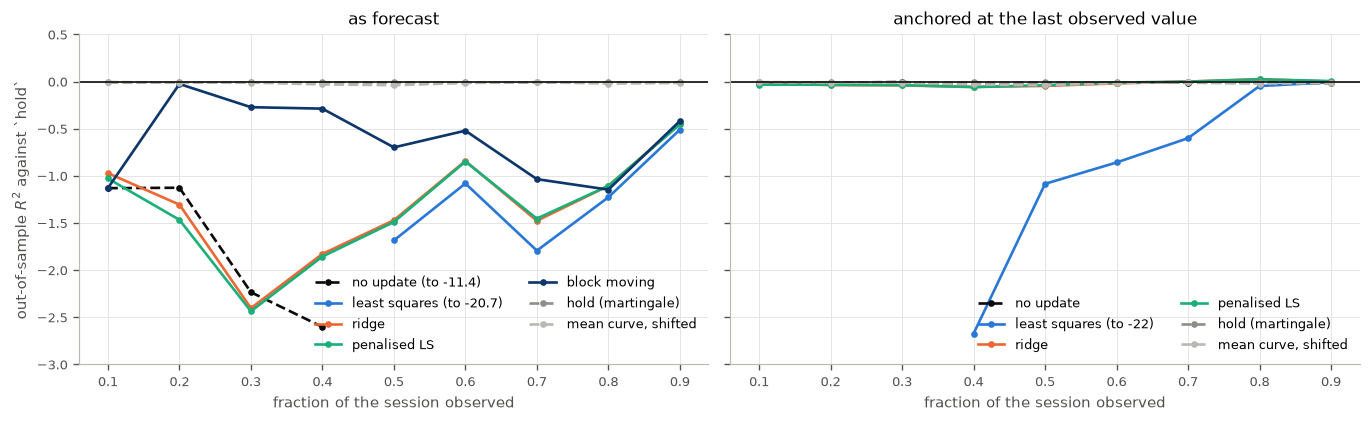

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.6), sharey=True)
for axis, frame, title in ((ax[0], plain["skill"].unstack("method"), "as forecast"),
                           (ax[1], anchored, "anchored at the last observed value")):
    for method in up.METHODS:
        if method not in frame.columns:
            continue
        shown, worst = style.clip_to(frame[method].to_numpy(), -3.0, 0.5)
        axis.plot(frame.index, shown, color=COLOUR[method], lw=1.6, marker="o", ms=3,
                  ls="--" if method in ("ts", "hold", "mean") else "-",
                  label=LABEL[method] + (f" (to {style.fmt(-worst)})" if worst else ""))
    axis.axhline(0, color=style.INK, lw=1.0)
    axis.set_ylim(-3.0, 0.5)
    axis.set_xlabel("fraction of the session observed")
    axis.set_title(title)
    axis.legend(ncol=2, loc="lower right")
ax[0].set_ylabel(r"out-of-sample $R^2$ against `hold`")
plt.tight_layout()
plt.show()

The two panels are the finding. Unanchored, the fitted updates sit one to two units of variance
below the martingale. Anchored, they collapse onto it: every method except least squares lands
between $-0.06$ and $+0.03$, and the paired tests no longer separate any of them from `hold`.

So essentially all of the deficit was level error, on a level the methods had been handed. A
truncated principal component expansion reconstructs a curve in an $L^2$ sense across the whole
domain, and nothing in that objective obliges the fitted curve to pass through the last point
of the observed block. On a cumulative return, where the level *is* most of the answer, that
costs more than everything else the method does.

And once it is removed, nothing is left. The anchored updates do not beat the martingale
either, which says the shape of the remainder carries no forecastable signal. The starkest
version of that is the row for the un-updated forecast: yesterday's forecast of the shape, slid
to meet today's observed level, is ahead of the full penalised least squares update over the
first half of the session and behind it over the second, with both within a few hundredths of
the martingale throughout. The morning is contributing nothing that yesterday did not already
have.

## 5. What the shrinkage is for

One thing in the tables does work exactly as intended, and it is worth separating from the rest
because it is a methodological point rather than a finding about markets. Plain least squares on
a short observed block is unusable, and the two penalised versions repair it.

MSFE, least squares against its penalised versions:
method       ols   ridge     pls
fraction                        
0.1       0.5197  0.0678  0.0698
0.2       0.7935  0.0843  0.0901
0.3       0.2079  0.0861  0.0870
0.4       0.1028  0.0680  0.0686
0.5       0.0460  0.0424  0.0427
0.6       0.0376  0.0332  0.0334
0.7       0.0329  0.0292  0.0289
0.8       0.0178  0.0168  0.0168
0.9       0.0114  0.0110  0.0110

paired, ridge against least squares:
  observed to 20%  mean difference  -44.6834, t = -5.116, p = 0.0000
  observed to 30%  mean difference   -6.6974, t = -4.073, p = 0.0002
  observed to 50%  mean difference   -0.1433, t = -1.097, p = 0.2780
  observed to 80%  mean difference   -0.0155, t = -0.540, p = 0.5919


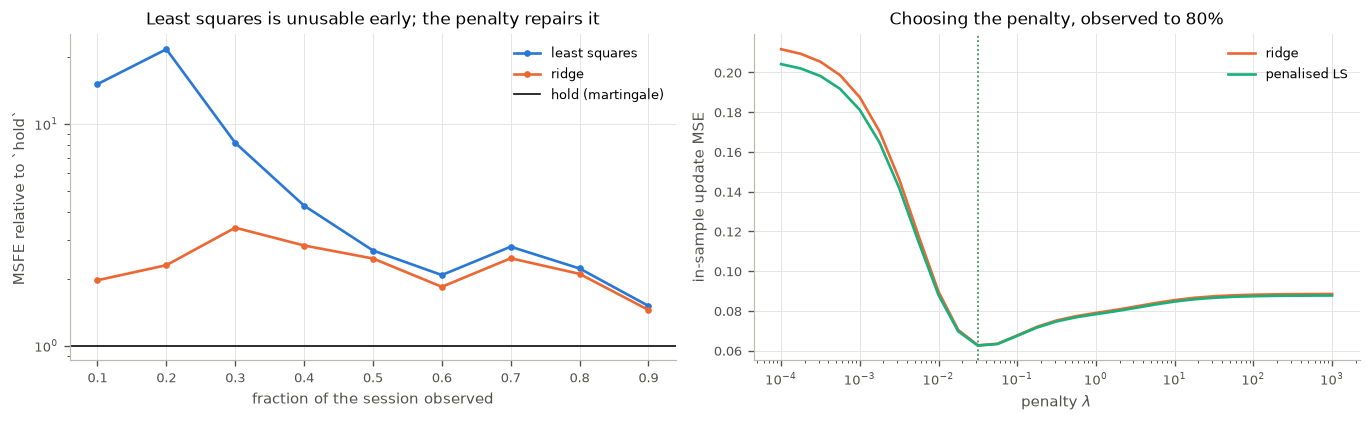

ridge          selected lambda 0.03162, index 10 of 28 on the grid
penalised LS   selected lambda 0.03162, index 10 of 28 on the grid


In [8]:
print("MSFE, least squares against its penalised versions:")
print(msfe[["ols", "ridge", "pls"]].round(4).to_string())

print("\npaired, ridge against least squares:")
for fraction in (0.2, 0.3, 0.5, 0.8):
    difference, t, p = paired("ridge", "ols", fraction)
    print(f"  observed to {fraction:.0%}  mean difference {difference:+9.4f}, "
          f"t = {t:+.3f}, p = {p:.4f}")

# What the criterion sees, at one update point.
sweep = {method: up.select_lambda(dec, m, method=method) for method in ("ridge", "pls")}

fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.6))
ax[0].plot(msfe.index, msfe["ols"] / msfe["hold"], color=COLOUR["ols"], lw=1.6, marker="o",
           ms=3, label=LABEL["ols"])
ax[0].plot(msfe.index, msfe["ridge"] / msfe["hold"], color=COLOUR["ridge"], lw=1.6, marker="o",
           ms=3, label=LABEL["ridge"])
ax[0].axhline(1.0, color=style.INK, lw=1.0, label="hold (martingale)")
ax[0].set_yscale("log")
ax[0].set_xlabel("fraction of the session observed")
ax[0].set_ylabel("MSFE relative to `hold`")
ax[0].set_title("Least squares is unusable early; the penalty repairs it")
ax[0].legend()

for method in ("ridge", "pls"):
    out = sweep[method]
    ax[1].plot(out["lambdas"], out["mse"], color=COLOUR[method], lw=1.6, label=LABEL[method])
    ax[1].axvline(out["lam_hat"], color=COLOUR[method], lw=1.0, ls=":")
ax[1].set_xscale("log")
ax[1].set_xlabel(r"penalty $\lambda$")
ax[1].set_ylabel("in-sample update MSE")
ax[1].set_title(f"Choosing the penalty, observed to {fraction:.0%}")
ax[1].legend()
plt.tight_layout()
plt.show()

for method in ("ridge", "pls"):
    out = sweep[method]
    print(f"{LABEL[method]:<14} selected lambda {out['lam_hat']:.4g}, "
          f"index {int(np.argmin(out['mse']))} of {out['mse'].size - 1} on the grid")

Least squares given a fifth of the session is worse than the martingale by a factor of nearly
twenty two; ridge at the same update point by a factor of two and a third. The penalty removes
about nine tenths of that excess, and the paired difference is significant at the two earliest
points tested and not at the two latest, which is exactly the pattern a variance problem should
show. It says nothing about whether either update is any good. It says the unpenalised version
is not a serious candidate on a block this short, and that is the entire reason the penalised
ones exist.

The penalty is chosen on the training days by the error the update is actually scored on, and
the minimum is interior to its grid rather than at either end. That matters: a criterion
measured on the reconstructed curves instead of the observed ones is exactly zero at every
penalty, because a truncated curve lies in the span of its own components, and it would select
whichever end of the grid it was handed.

## 6. The intervals

The replication notebook found that the intervals were the part of the pipeline that survived
contact with the data. The same construction is available here, resampling the in-sample update
errors on the training days, and the same question applies: does the band around an updated
forecast do better than the band around the thing that fits nothing?

interval score and coverage of the 80% bands, unanchored:
method      hold    mean     ols     pls   ridge      ts
fraction                                                
0.1       0.6932  0.6894  2.2140  0.8873  0.8806  0.9558
0.2       0.7009  0.7106  2.9513  0.9751  0.9577  0.9812
0.3       0.5715  0.5891  1.4617  0.9975  0.9627  1.0093
0.4       0.5521  0.5599  1.0228  0.8811  0.8673  1.0704
0.5       0.4606  0.4714  0.7158  0.7230  0.7264  1.0838
0.6       0.4902  0.4888  0.6872  0.6428  0.6542  1.1108
0.7       0.3941  0.4064  0.6600  0.6175  0.6177  1.1645
0.8       0.3309  0.3366  0.5032  0.4931  0.4900  1.1635
0.9       0.2916  0.2951  0.4098  0.4016  0.3989  1.0942

method      hold    mean     ols     pls   ridge      ts
fraction                                                
0.1       0.8746  0.8918  0.8056  0.8177  0.8301  0.8256
0.2       0.8638  0.8698  0.6578  0.7641  0.8044  0.8514
0.3       0.8727  0.8775  0.7378  0.7567  0.7691  0.8211
0.4       0.8685  0.8609  0.7

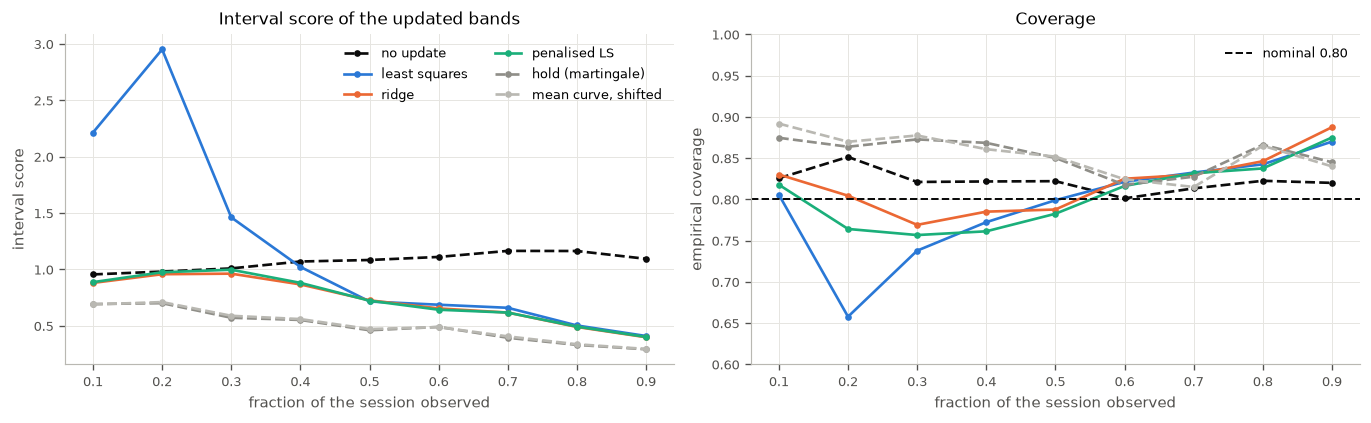

In [9]:
bands = plain[["iscore", "coverage"]].dropna()
print("interval score and coverage of the 80% bands, unanchored:")
print(bands["iscore"].unstack("method").round(4).to_string())
print()
print(bands["coverage"].unstack("method").round(4).to_string())

fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.6))
for method in [m for m in up.METHODS if m != "block"]:
    series = bands.xs(method, level="method")
    ax[0].plot(series.index, series["iscore"], color=COLOUR[method], lw=1.6, marker="o", ms=3,
               ls="--" if method in ("ts", "hold", "mean") else "-", label=LABEL[method])
    ax[1].plot(series.index, series["coverage"], color=COLOUR[method], lw=1.6, marker="o",
               ms=3, ls="--" if method in ("ts", "hold", "mean") else "-")
ax[1].axhline(0.8, color=style.INK, lw=1.2, ls="--", label="nominal 0.80")
ax[0].set_ylabel("interval score")
ax[1].set_ylabel("empirical coverage")
ax[1].set_ylim(0.6, 1.0)
for axis, title in zip(ax, ("Interval score of the updated bands", "Coverage")):
    axis.set_xlabel("fraction of the session observed")
    axis.set_title(title)
ax[0].legend(ncol=2)
ax[1].legend()
plt.tight_layout()
plt.show()

The bands cover close to their nominal rate for every method but least squares, which misses
badly over the first third of the session and recovers once its point forecast does. That
calibration is a real property and the one thing in this notebook that works as advertised.

The ordering, though, is the same one again: the martingale's band has the best interval score
at seven of the nine update points and the shifted mean curve at the other two, and every band
narrows through the day as the remaining session shortens. Scoring a band well and forecasting
are different achievements, and only the first is on offer here.

## 7. What dynamic updating says

**Shang's claim reproduces, from the middle of the session onwards.** Using the observed part
of a day to revise the forecast of the rest of it removes most of the error of the un-updated
forecast, and the gain grows steadily: by the last fifth of the session the penalised updates
have removed above 82% of it. Earlier than 40% they remove none, being worse than not updating
at all, which the papers do not report and which section 5 accounts for.

**The gain is the observed level, not a forecast.** Carrying the last observed value forward
beats every method at every update point in the sweep, and the gap is significant at each of the
three points tested. Anchoring the methods at that value closes almost the whole of it and
leaves them indistinguishable from the martingale, so what the updates were losing was not shape
but level, on a number they had been handed. What they add once that is fixed is nothing
measurable.

**The shrinkage is doing genuine work, at a question below this one.** Least squares on a
short observed block is worse than the martingale by more than an order of magnitude, and the
two penalised versions remove about nine tenths of that excess. That is a real methodological
result and it is orthogonal to whether the updated forecast is any good. It is also why the
penalty has to be chosen against the observed curves rather than their reconstructions, which
would make the criterion identically zero.

**Read together with the replication, the two notebooks say one thing.** There, the day-ahead
forecast could not beat the flat forecast; here, the updated forecast cannot beat the
martingale. Both are statements that the conditional mean of this curve process carries nothing,
at either horizon. The dependence in intraday price curves is real, and
`notebooks/overnight_jumps.ipynb` locates it in the conditional variance, which no linear
operator on the curve represents and no amount of intraday information changes.

What the updating machinery does buy, and it is not nothing, is a well-calibrated band that
narrows as the session goes on. For a quantity whose conditional mean is a martingale, that is
the correct output: not where the rest of the day will go, but how far it might.